# 演習1：分子の回路を比較し、IBM実機へ送信する（16:10–17:00）

**問い**：状態や時間発展を近似すると、操作数と精度はどう変わるでしょうか。
MPS/MPOの知識は必要ありません。配布済み回路を使います。

- 16:10–16:20：分子と目標状態の確認。
- 16:20–16:35：準備回路・時間発展回路を比較。
- 16:35–16:50：測定計画を確認して実機へ投入。
- 16:50–17:00：記録ファイルを保存し、討論。

6チームの初期割当例：1〜3組はエチレンのcompact、4〜6組はエチレンのreference。
同じ条件の繰返しを比較できます。referenceの実機深さが過大な場合は、短い時間設定に絞るかcompactへ変更します。

In [1]:
# GitHub → Colab / ローカルの共通セットアップ
import sys, subprocess, importlib.util
from pathlib import Path
GITHUB_REPOSITORY = "https://github.com/QS-laboratory/IBM_handson.git"
GITHUB_REF = "main"  # 配布時には講師が検証済みタグまたはコミットへ固定します
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "qiskit==2.4.1", "qiskit-ibm-runtime==0.43.1", "pylatexenc==2.10"], check=True)
    checkout = Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git", "clone", GITHUB_REPOSITORY, str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "fetch", "origin", GITHUB_REF, "--depth", "1"], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--detach", "FETCH_HEAD"], check=True)
    WORKSHOP_ROOT = checkout / "hands_on"
else:
    candidates = [Path.cwd(), Path.cwd()/"hands_on", Path.cwd().parent]
    WORKSHOP_ROOT = next(p for p in candidates if (p/"src/workshop.py").exists())
sys.path.insert(0, str(WORKSHOP_ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import *
import qiskit
print("Qiskit:", qiskit.__version__)
print("教材:", WORKSHOP_ROOT)
print("実機への送信は、明示的に有効化したセルだけが行います。")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def show_circuit(qc):
    try:
        figure = qc.draw("mpl", fold=90)
        display(figure)
        plt.close(figure)
    except ImportError:
        print(qc.draw("text", fold=90))

Qiskit: 2.4.1
教材: /Users/sato/project/FTQC_HandsOn/hands_on
実機への送信は、明示的に有効化したセルだけが行います。


対象: ethylene 基底: STO-3G CAS: (2, 2)
一重項・三重項の S(S+1): [0.0, 2.0]


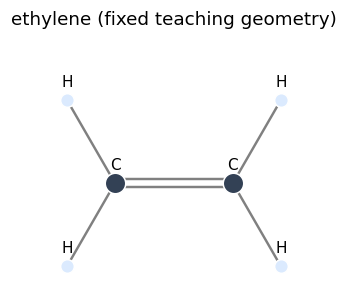

In [2]:
MOLECULE = "ethylene"  # 主題材の拡張: "butadiene"
VARIANT = "compact"    # 比較用: "reference"
TEAM = "team01"       # 各チームで変更
SHOTS = 1024
meta, arrays = load_model(MOLECULE)
summary = circuit_summary(MOLECULE)
print("対象:", MOLECULE, "基底:", meta["basis"], "CAS:", (meta["active_electrons"], meta["active_spatial_orbitals"]))
print("一重項・三重項の S(S+1):", meta["s_squared"])
plot_molecule(MOLECULE); plt.show()

## 状態準備：どんな状態を作るか
補助量子ビットと分子の状態を組み合わせ、
$(|0\rangle|S_0\rangle+|1\rangle|T_1,M_S=0\rangle)/\sqrt{2}$ を目標とします。
補助量子ビットは最大の番号、分子の系はq0から並びます。

referenceは小さな模型の厳密状態を汎用的に分解した準備回路です。
compactはRYと近接CNOTの浅い形に合わせた近似回路です。忠実度1なら目標状態と一致します。

**見ること**：操作数だけでなく、目標状態への近さを比較してください。

reference fidelity= 1.0 CX= 24 depth= 84
compact fidelity= 1.0 CX= 20 depth= 45


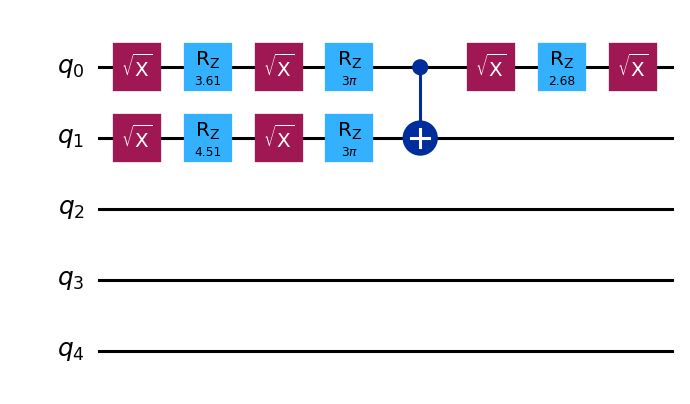

In [3]:
from qiskit.quantum_info import Statevector
joint_target = np.concatenate([arrays["singlet"], arrays["triplet"]])/np.sqrt(2)
for kind in ["reference", "compact"]:
    prep = load_circuit(MOLECULE, f"prep_{kind}")
    fidelity = abs(np.vdot(joint_target, Statevector.from_instruction(prep).data))**2
    cost = summary["circuits"][f"prep_{kind}"]
    print(kind, "fidelity=", round(fidelity,6), "CX=",cost["cx_count"], "depth=",cost["depth"])
# 回路全体は長いため、最初の12操作だけを表示します。
from qiskit import QuantumCircuit
preview = QuantumCircuit(meta["total_qpde_qubits"])
original = load_circuit(MOLECULE,"prep_compact")
for instruction in original.data[:12]:
    # 配布回路内のビット番号を明示的に引き継ぎます。
    indices = [original.find_bit(q).index for q in instruction.qubits]
    preview.append(instruction.operation, indices)
show_circuit(preview)

## 時間発展：どこまで短くできるか

referenceは6分割の一次Trotter回路、compactは1分割の短いPauli積回路の時間係数を事前に調整したものです。
ここでいう短縮は論文のMPO回路最適化そのものではなく、分子で精度と操作数の関係を学ぶための例です。

両者を、別途作った密な行列指数の厳密時間発展と比較します。referenceも有限分割の近似です。
表示するCX数と深さは全結合・共通基底での値で、IBM実機への配置後には変わります。

evol_reference CX= 188 depth= 422 relative error= 0.0007817307040315708
evol_compact CX= 33 depth= 72 relative error= 0.0046850628272696706


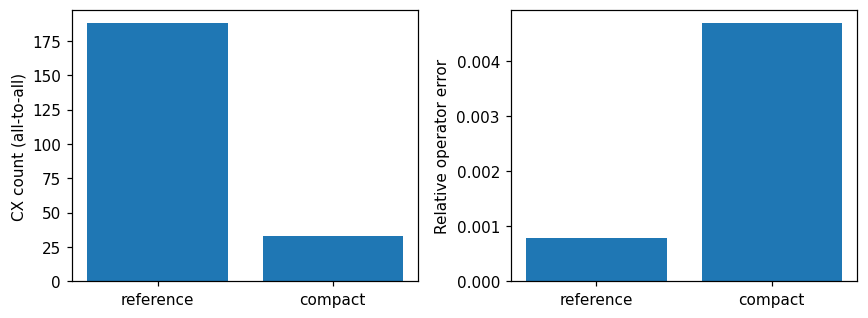

In [4]:
for key in ["evol_reference", "evol_compact"]:
    cost = summary["circuits"][key]
    error_key = "reference_relative_operator_error" if key.endswith("reference") else "relative_operator_error"
    print(key, "CX=",cost["cx_count"], "depth=",cost["depth"],
          "relative error=",summary["evolution"][error_key])
fig, axes = plt.subplots(1,2,figsize=(8,3))
keys=["evol_reference","evol_compact"]
axes[0].bar(["reference","compact"],[summary["circuits"][k]["cx_count"] for k in keys])
axes[0].set_ylabel("CX count (all-to-all)")
axes[1].bar(["reference","compact"],[summary["evolution"]["reference_relative_operator_error"],summary["evolution"]["relative_operator_error"]])
axes[1].set_ylabel("Relative operator error")
plt.tight_layout(); plt.show()

## 同じ回路を位相差推定へ接続する

準備 → 系の時間発展を反復 → 補助の位相操作 → 準備の逆回路 → 全ビット測定、の順です。
**配布された浅い回路を、そのまま連結します。** 密な行列に戻して汎用ゲートへ再分解することはしません。

まずノイズなしで計算します。ショットノイズと実機ノイズは次の演習で分けて考えます。
基準エネルギー差は正解合わせ用にのみ表示し、測定計画はそれを中心に設定していません。

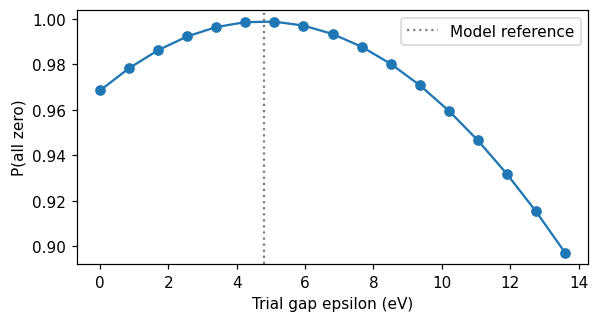

In [5]:
epsilon_values = np.linspace(0,.5,17)
steps = 4
probs = [zero_probability(MOLECULE,eps,steps,VARIANT) for eps in epsilon_values]
fig, ax = plt.subplots(figsize=(6,3))
ax.plot(epsilon_values*HARTREE_TO_EV,probs,"o-")
ax.axvline(meta["gap_ev"],color="gray",ls=":",label="Model reference")
ax.set(xlabel="Trial gap epsilon (eV)",ylabel="P(all zero)")
ax.legend(); plt.show()

## 実機投入計画

同じ分子の測定を3ラウンド行います。初期設定は各ラウンド9点、1点1024ショットで、合計27回路・27,648ショットです。
ここでいうラウンドは時間発展の長さが異なる測定セットで、探索点は事前に固定しています。
結果を見て次の探索点を変える適応的な制御は、発展課題です。

当日の実機の状態と講師の指示で、まず1ラウンドだけに短縮できます。
エチレンなら `step_counts=[2]` と指定します。時間の単位は原子単位です。
ブタジエンは既定の計画でも非常に深くなるので、講師の検証前には実機投入しないでください。

In [6]:
plan = make_plan(MOLECULE, VARIANT, TEAM, SHOTS)
print("Circuits:",len(plan["rows"]),"Shots:",sum(r["shots"] for r in plan["rows"]))
for iteration in sorted({r["iteration"] for r in plan["rows"]}):
    row=next(r for r in plan["rows"] if r["iteration"]==iteration)
    native_cx=2*summary["circuits"][f"prep_{VARIANT}"]["cx_count"]+row["steps"]*summary["circuits"][f"evol_{VARIANT}"]["cx_count"]
    print("Round",iteration,"time=",row["time_atomic_units"],"steps=",row["steps"],"CX before routing ~",native_cx)
write_json(OUTPUT_DIR/f"{TEAM}_plan.json",plan)

Circuits: 27 Shots: 27648
Round 1 time= 1.0 steps= 2 CX before routing ~ 106
Round 2 time= 2.0 steps= 4 CX before routing ~ 172
Round 3 time= 4.0 steps= 8 CX before routing ~ 304


In [7]:
# 接続を試すときだけTrueに変更。APIキーをコードや出力へ書かないでください。
CONNECT_IBM = False
INSTANCE_CRN = ""  # 今回利用できる所属企業の枠、または講師が案内するFlex枠
BACKEND_NAME = ""  # 接続後、利用可能な実機から講師と相談して指定
service = None
if CONNECT_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService
    if not INSTANCE_CRN:
        raise ValueError("利用権限のあるインスタンスのCRNを指定してください")
    if IS_COLAB:
        from google.colab import userdata
        api_key = userdata.get("IBM_QUANTUM_API_KEY")
    else:
        from getpass import getpass
        api_key = getpass("IBM Quantum API key: ")
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key, instance=INSTANCE_CRN)
    del api_key
    print("利用可能な実機:", [b.name for b in service.backends(operational=True, simulator=False)])
else:
    print("IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。")

IBM接続はスキップ。ローカル演習と配布データの解析は続けられます。


### 配置後の深さを確認（送信しない）

講師と接続先・利用枠を確認し、代表回路をIBM実機の命令セットへ変換します。
長い回路で信号が得られるとは限りません。ここでの数値を見て測定計画を短縮します。

In [8]:
PREVIEW_ISA = False
if PREVIEW_ISA:
    if service is None or not BACKEND_NAME: raise ValueError("IBM接続と実機名が必要です")
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    backend=service.backend(BACKEND_NAME)
    pm=generate_preset_pass_manager(backend=backend,optimization_level=3,seed_transpiler=11)
    for iteration in sorted({r["iteration"] for r in plan["rows"]}):
        row=next(r for r in plan["rows"] if r["iteration"]==iteration)
        isa=pm.run(qpde_circuit(MOLECULE,row["epsilon_hartree"],row["steps"],VARIANT))
        print("round",iteration,"ISA depth",isa.depth(),"2-qubit operations",sum(len(op.qubits)==2 for op in isa.data))

### チーム代表者：送信する

以下は実機利用枠を消費します。講師の合図で `RUN_IBM = True` に変更します。
各ラウンドの送信直後にジョブIDを記録します。途中で止まった場合は、保存済み記録を先に確認してください。
再実行による重複送信を防ぐため、同じ記録ファイルがあると送信を停止します。

In [9]:
RUN_IBM = False
record_path = OUTPUT_DIR / f"{TEAM}_submission.json"
if RUN_IBM:
    if service is None or not BACKEND_NAME: raise ValueError("IBM接続と実機名が必要です")
    if MOLECULE == "butadiene":
        raise ValueError("ブタジエン実機版は講師の事前ベンチマーク後に有効化してください")
    submission = submit_ibm(plan,service,BACKEND_NAME,record_path)
    print("Saved:",record_path)
    print("Job IDs:",[job["job_id"] for job in submission["jobs"]])
else:
    print("実機送信なし。次の演習は配布の模擬測定データでも進められます。")

実機送信なし。次の演習は配布の模擬測定データでも進められます。


### 記録ファイルを持ち出す
Colabのファイル欄から `outputs/..._submission.json` をダウンロードしてください。
APIキーはこの記録に含みません。次の演習ノートでアップロードし、再認証して結果を取得します。
ジョブID・実機名・回路条件を残すことは、再現性のための作業です。

**討論（休憩前）**：ゲート数が小さい回路は常に優れているでしょうか。準備と時間発展のどちらの誤差が結果へ影響するでしょうか。